In [1]:
# Import libraries, set pathwas and import data 
import numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

SEED = 12345
rng = np.random.default_rng(SEED)

MORPH = Path("results/morphology"); OUT = Path("results/models"); FIGS = Path("results/functions/figures")
FIGS.mkdir(parents=True, exist_ok=True)

# Results from notebooks 02-04
res = pd.read_csv(OUT / "meta_results_empirical.csv")        # one row per gene x axis (beta, z, q, empirical q, het_p, ...)
fz = pd.read_csv(OUT / "meta_feature_z.csv", index_col=0)    # gene x individual-feature z-scores
load = pd.read_csv(MORPH / "pc_loadings.csv", index_col=0)   # feature x axis loadings

print(res.shape, fz.shape, load.shape)

(55736, 18) (13934, 19) (19, 4)


# 1. Morphology axis  

In [2]:
# Identify five features that load most strongly on each axis (sign = direction of the axis)
for a in load.columns:
    top = load[a].reindex(load[a].abs().sort_values(ascending=False).index).head(5)
    print(a)
    print(top.round(2).to_string(), "\n")

wPC1
dendrite total length                      0.38
dendrite max Euclidean dist                0.35
dendrite robust height                     0.34
dendrite bifurcation standard deviation    0.33
dendrite max branch order                  0.33 

wPC2
stems exiting to the sides           0.50
stems exiting down                  -0.39
dendrite first bifurcation moment   -0.36
dendrite robust width                0.34
dendrite z-bias                     -0.34 

wPC3
stems exiting to the sides          -0.49
stems exiting up                     0.48
dendrite z-bias                     -0.46
dendrite first bifurcation moment   -0.44
dendrite max segment length          0.18 

wPC4
dendrite branch points         0.34
dendrite max Euclidean dist   -0.31
dendrite log max tortuosity    0.31
dendrite robust height        -0.30
dendrite max segment length   -0.30 



In [3]:
# Top candidate genes per axis 

AXIS_NAME = {"wPC1": "overall dendrite size",
             "wPC2": "lateral spread vs downward reach",
             "wPC3": "upward vs sideways orientation",
             "wPC4": "compact/bushy vs sparse/far-reaching"}

# In how many families does each gene's effect point the same way as the combined effect?
bcols = [c for c in res.columns if c.startswith("beta_")]
b = res[bcols]
res["same_sign"] = (np.sign(b).eq(np.sign(res["beta"]), axis=0) & b.notna()).sum(axis=1)
res["consistent"] = res["same_sign"].astype(str) + "/" + res["n_families"].astype(str)
res["axis_name"] = res["axis"].map(AXIS_NAME)

top = res.sort_values("p_emp").groupby("axis").head(5).sort_values(["axis", "p_emp"])
top[["axis", "axis_name", "gene", "beta", "z", "q_emp", "consistent", "het_p"]].round(3)

,axis,axis_name,gene,beta,z,q_emp,consistent,het_p
4212,wPC1,overall dendrite size,Gm11989,-0.105,-4.668,0.536,6/7,0.708
9275,wPC1,overall dendrite size,Pdk1,0.451,4.451,0.544,5/6,0.450
6663,wPC1,overall dendrite size,Hddc2,-1.154,-4.174,0.721,2/2,0.000
1913,wPC1,overall dendrite size,Cenpo,-1.197,-4.112,0.721,1/2,0.000
9816,wPC1,overall dendrite size,Prdm8,-0.697,-4.017,0.721,3/3,0.005
15686,wPC2,lateral spread vs downward reach,Ccn2,0.957,5.127,0.306,3/3,0.255
23752,wPC2,lateral spread vs downward reach,Prdx2,-0.571,-4.801,0.450,5/7,0.017
22913,wPC2,lateral spread vs downward reach,Nxph4,0.925,4.553,0.536,2/2,0.866
17696,wPC2,lateral spread vs downward reach,Foxp2,-1.322,-4.508,0.536,2/2,0.271
21155,wPC2,lateral spread vs downward reach,Kbtbd3,-0.429,-4.493,0.536,5/7,0.404


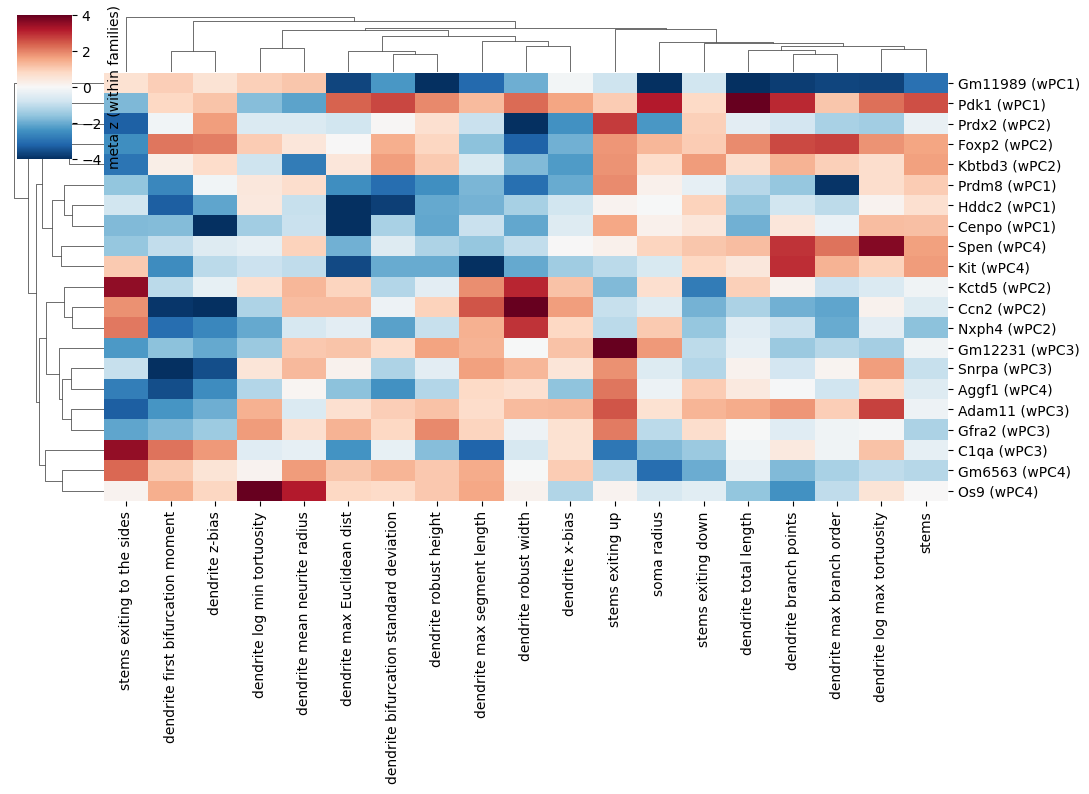

In [4]:
# Candidate genes against individual morphology features 

import seaborn as sns          

# Candidates: top 5 per axis plus Kctd5 (most consistent across families)
genes = list(dict.fromkeys(top["gene"].tolist() + ["Kctd5"]))
axis_of = res.sort_values("p_emp").drop_duplicates("gene").set_index("gene")["axis"]   # each gene's strongest axis

H = fz.loc[genes]
H.index = [f"{g} ({axis_of[g]})" for g in genes]

cg = sns.clustermap(H, cmap="RdBu_r", center=0, vmin=-4, vmax=4, figsize=(11, 8),
                    xticklabels=True, yticklabels=True, dendrogram_ratio=(0.1, 0.12),
                    cbar_kws={"label": "meta z (within families)"})
cg.savefig(FIGS / "gene_feature_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Gene set enrichment analysis 

In [5]:
import gseapy as gp

axes = ["wPC1", "wPC2", "wPC3", "wPC4"]
gsea = []
for a in axes:
    d = res[res.axis == a].dropna(subset=["z"]).copy()
    d["sym"] = d["gene"].str.upper()                       # GO libraries use upper-case symbols
    rnk = d.drop_duplicates("sym").set_index("sym")["z"].sort_values(ascending=False)
    pr = gp.prerank(rnk=rnk, gene_sets="GO_Biological_Process_2023", min_size=15, max_size=300,
                    permutation_num=1000, seed=SEED, threads=4, outdir=None, verbose=False)
    t = pr.res2d.copy(); t["axis"] = a
    gsea.append(t)

gsea = pd.concat(gsea, ignore_index=True)
for c in ["NES", "NOM p-val", "FDR q-val"]:
    gsea[c] = gsea[c].astype(float)
gsea.to_csv(OUT / "gsea_prerank_GO_BP.csv", index=False)

gsea.sort_values("FDR q-val").head(12)[["axis", "Term", "NES", "NOM p-val", "FDR q-val"]].round(3)

,axis,Term,NES,NOM p-val,FDR q-val
0,wPC1,Cytoplasmic Translation (GO:0002181),-2.679,0.000,0.000
5319,wPC4,Oxidative Phosphorylation (GO:0006119),-2.553,0.000,0.000
5320,wPC4,Aerobic Electron Transport Chain (GO:0019646),-2.473,0.000,0.000
5321,wPC4,Proton Motive Force-Driven Mitochondrial ATP S...,-2.468,0.000,0.000
5322,wPC4,Mitochondrial ATP Synthesis Coupled Electron T...,-2.442,0.000,0.000
5323,wPC4,Proton Motive Force-Driven ATP Synthesis (GO:0...,-2.367,0.000,0.000
5324,wPC4,"Mitochondrial Electron Transport, NADH To Ubiq...",-2.286,0.000,0.001
5325,wPC4,Aerobic Respiration (GO:0009060),-2.251,0.000,0.001
5326,wPC4,Cellular Respiration (GO:0045333),-2.132,0.000,0.005
1,wPC1,Macromolecule Biosynthetic Process (GO:0009059),-2.139,0.000,0.026


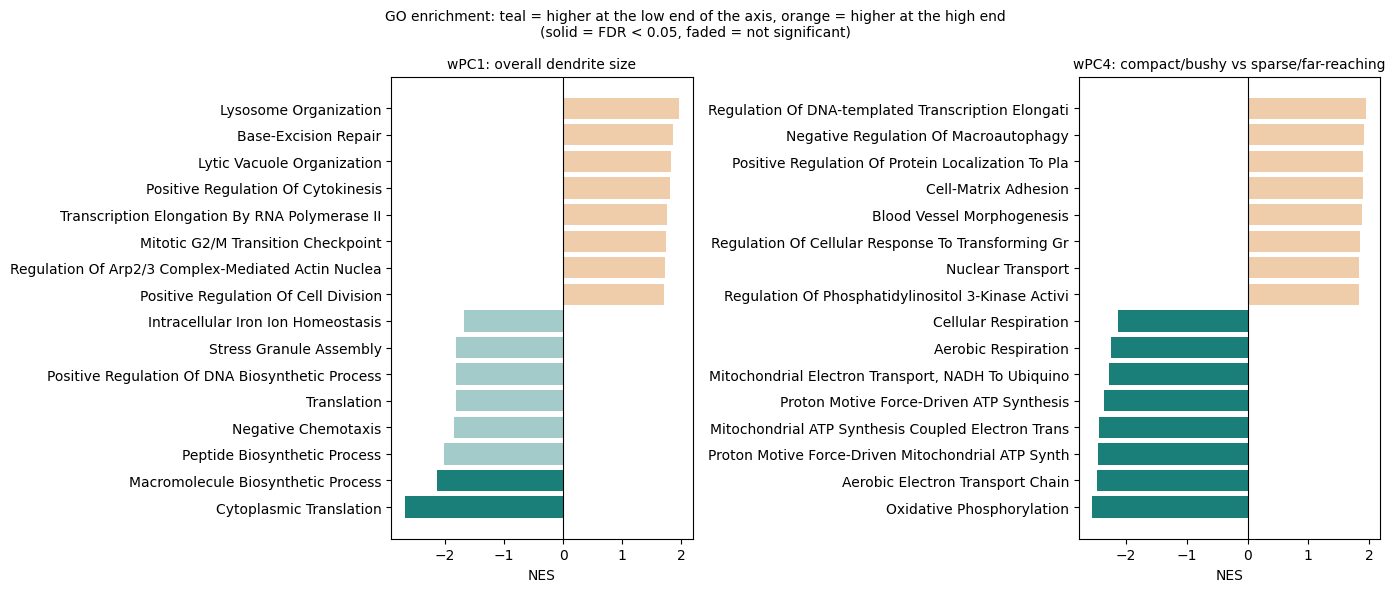

In [6]:
def nes_bars(ax, a, n=8):
    d = gsea[gsea["axis"] == a].copy()
    d["term"] = d["Term"].str.replace(r" \(GO:\d+\)", "", regex=True).str.slice(0, 50)
    d = pd.concat([d.nlargest(n, "NES"), d.nsmallest(n, "NES")]).sort_values("NES")
    bars = ax.barh(d["term"], d["NES"], color=np.where(d["NES"] < 0, "#1b7f79", "#d9822b"))
    for b, q in zip(bars, d["FDR q-val"]):
        if q >= 0.05:
            b.set_alpha(0.4)                                  # faded = not significant at FDR 5%
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f"{a}: {AXIS_NAME[a]}", fontsize=10)
    ax.set_xlabel("NES")

fig, axs = plt.subplots(1, 2, figsize=(14, 6))
for ax, a in zip(axs, ["wPC1", "wPC4"]):
    nes_bars(ax, a)
fig.suptitle("GO enrichment: teal = higher at the low end of the axis, orange = higher at the high end\n"
             "(solid = FDR < 0.05, faded = not significant)", fontsize=10)
fig.tight_layout()
fig.savefig(FIGS / "gsea_nes_bars.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. Do the top GO terms replicate across families? 

In [7]:
# For the genes in each term, we compare each family's effects with all genes in that family. 
# A real effect should point the same way in most families. 

lib = gp.get_library("GO_Biological_Process_2023")          # term -> list of gene symbols
bcols = [c for c in res.columns if c.startswith("beta_")]

for a, term, sign in [("wPC4", "Oxidative Phosphorylation (GO:0006119)", -1),
                      ("wPC1", "Cytoplasmic Translation (GO:0002181)", -1)]:
    d = res[res.axis == a].reset_index(drop=True)
    inset = d["gene"].str.upper().isin(lib[term])
    shift = d.loc[inset, bcols].mean() - d[bcols].mean()                  # term genes vs all genes, per family
    frac = (np.sign(d.loc[inset, bcols]) == sign).mean()                  # share of term genes with the expected sign
    print(f"\n{a} | {term} | {inset.sum()} genes (expected sign: {'negative' if sign < 0 else 'positive'})")
    print(pd.DataFrame({"mean beta shift": shift.round(3), "share expected sign": frac.round(2)}).to_string())


wPC4 | Oxidative Phosphorylation (GO:0006119) | 46 genes (expected sign: negative)
            mean beta shift  share expected sign
beta_IT              -0.051                 0.52
beta_Pvalb           -0.250                 0.80
beta_Sst             -0.223                 0.78
beta_CT              -0.224                 0.83
beta_Vip             -0.124                 0.63
beta_Lamp5            0.147                 0.46
beta_ET               0.086                 0.30

wPC1 | Cytoplasmic Translation (GO:0002181) | 87 genes (expected sign: negative)
            mean beta shift  share expected sign
beta_IT              -0.176                 0.75
beta_Pvalb           -0.070                 0.71
beta_Sst             -0.053                 0.57
beta_CT              -0.062                 0.55
beta_Vip             -0.547                 0.90
beta_Lamp5            0.237                 0.25
beta_ET               0.453                 0.25


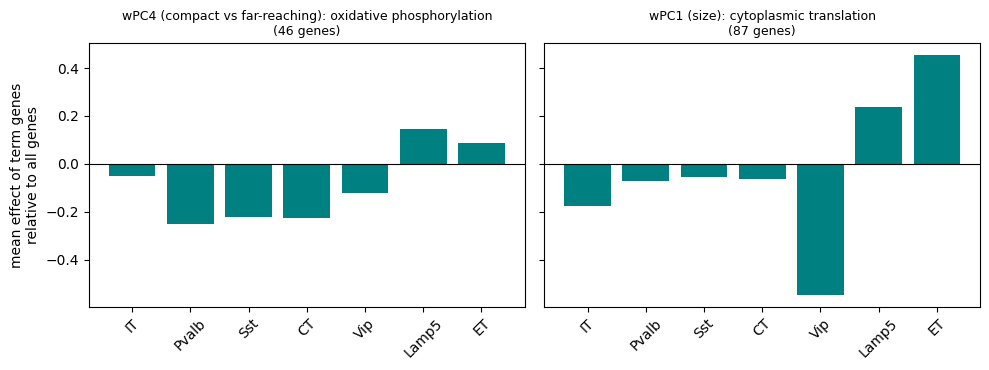

In [8]:
# Make figures 
terms = [("wPC4", "Oxidative Phosphorylation (GO:0006119)", "wPC4 (compact vs far-reaching): oxidative phosphorylation"),
         ("wPC1", "Cytoplasmic Translation (GO:0002181)", "wPC1 (size): cytoplasmic translation")]

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, (a, term, title) in zip(axs, terms):
    d = res[res.axis == a].reset_index(drop=True)
    inset = d["gene"].str.upper().isin(lib[term])
    shift = d.loc[inset, bcols].mean() - d[bcols].mean()
    shift.index = [c.replace("beta_", "") for c in shift.index]
    ax.bar(shift.index, shift.values, color="teal")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"{title}\n({inset.sum()} genes)", fontsize=9)
    ax.tick_params(axis="x", rotation=45)
axs[0].set_ylabel("mean effect of term genes\nrelative to all genes")
fig.tight_layout()
fig.savefig(FIGS / "negative_gsea_family.png", dpi=150)
plt.show()

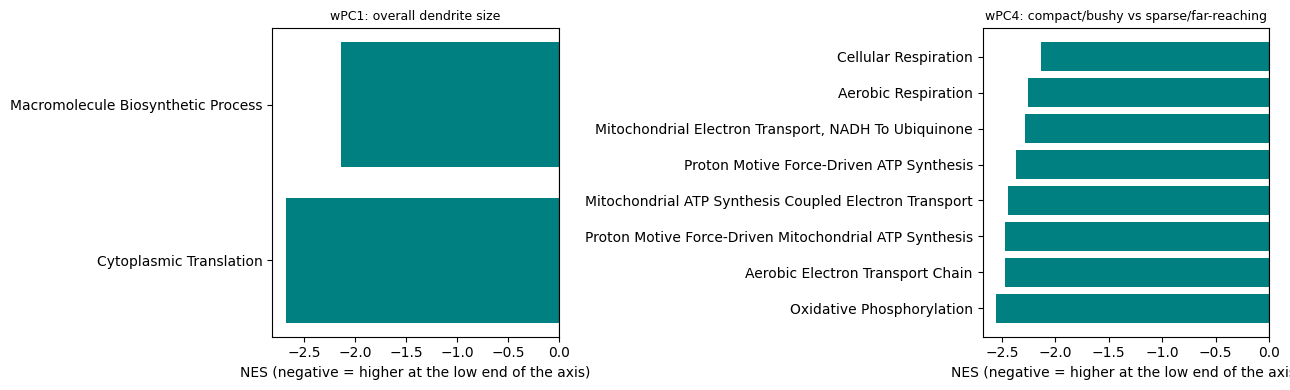

In [9]:
# Bar plot 
g = gsea[gsea["FDR q-val"] < 0.05].copy()
g["term"] = g["Term"].str.replace(r" \(GO:\d+\)", "", regex=True).str.slice(0, 55)
g["abs_nes"] = g["NES"].abs()
g = g.sort_values("abs_nes", ascending=False).groupby("axis").head(8)          # top 8 terms per axis

axes_hit = g["axis"].unique()
fig, axs = plt.subplots(1, len(axes_hit), figsize=(6.5 * len(axes_hit), 4), squeeze=False)
for ax, a in zip(axs[0], axes_hit):
    d = g[g.axis == a].sort_values("NES")
    ax.barh(d["term"], d["NES"], color="teal")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f"{a}: {AXIS_NAME[a]}", fontsize=9)
    ax.set_xlabel("NES (negative = higher at the low end of the axis)")
fig.tight_layout()
fig.savefig(FIGS / "negative_gsea_top_terms.png", dpi=150)
plt.show()